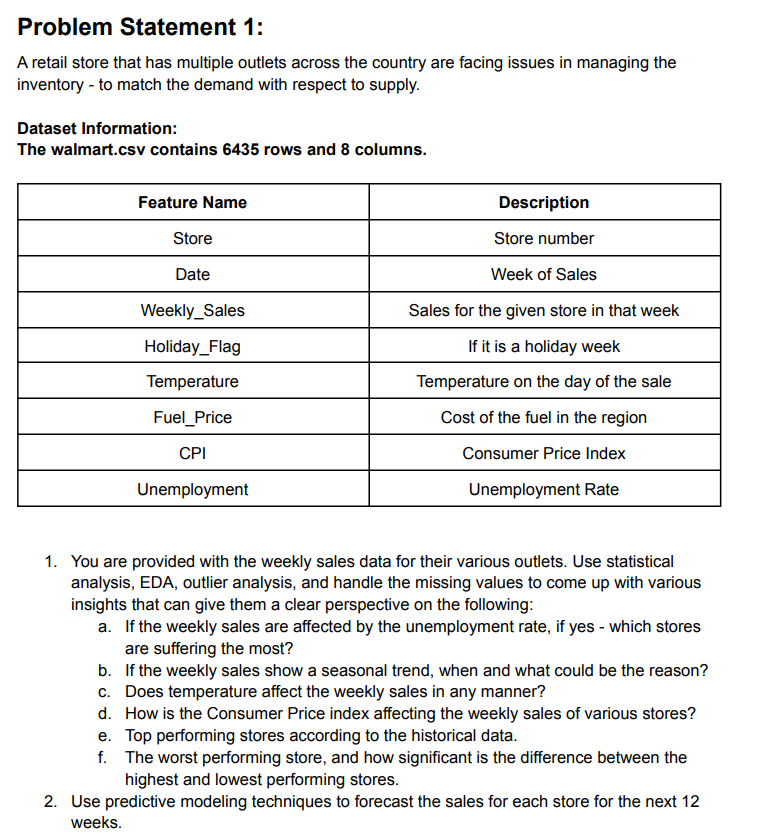

## Walmart Sales Analysis & Forecasting

### Task 1: Statistical analysis, EDA, outlier analysis, missing values

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("Walmart DataSet.csv")
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


### 1.1 Data loading and understanding

In [3]:
df.shape

(6435, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


date is in object format need to convert it into datetime

In [5]:
df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


**What describe() shows**
- 6,435 rows in every column, so no missing values.
- Store is only an ID (1 to 45), so its mean and std mean nothing. Holiday_Flag is 0/1, and about 7% of weeks are holiday weeks.
- Weekly_Sales: the mean (1.05M) is above the median (0.96M), so it is right-skewed. The max (3.82M) is far above the 75% value (1.42M), which suggests high outliers.
- Unemployment: the max (14.3) is far above the 75% value (8.6), so there may be outliers.
- CPI: a big gap between the 25% value (131.7) and the median (182.6) suggests groups of stores in different regions.
- Temperature (-2 to 100, Fahrenheit) and Fuel_Price (2.47 to 4.47) look plausible.

### 1.2 Data preprocessing
`Date` is stored as text (object), so it is converted to datetime (day first).

In [6]:
df['Date']=pd.to_datetime(df['Date'],dayfirst=True)

In [7]:
df.info() #date converted to datetime

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 402.3 KB


In [8]:
df.isnull().sum() #no null  values

,0
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


In [9]:
df.duplicated().sum() #No duplicates

np.int64(0)

No missing values and no duplicate rows were found, so nothing needs to be filled or dropped.

In [10]:
df.columns

Index(['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment'],
      dtype='object')

### 1.3 Outlier analysis
Boxplots of the numeric columns using all rows together. Weekly_Sales and Unemployment clearly show outliers, so they are checked per store next.

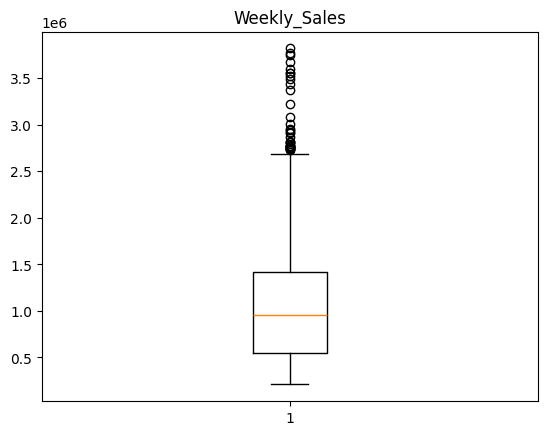

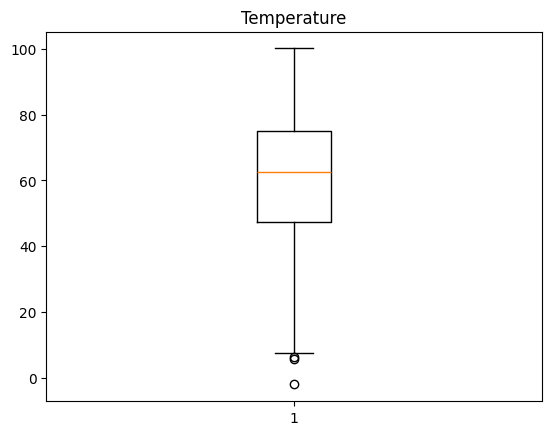

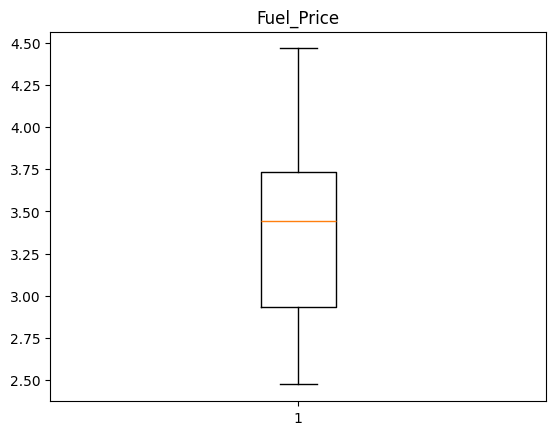

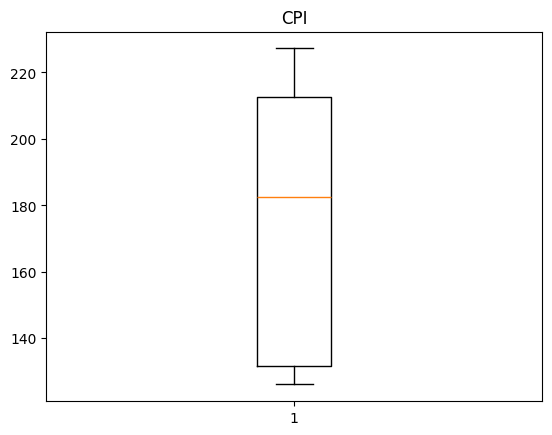

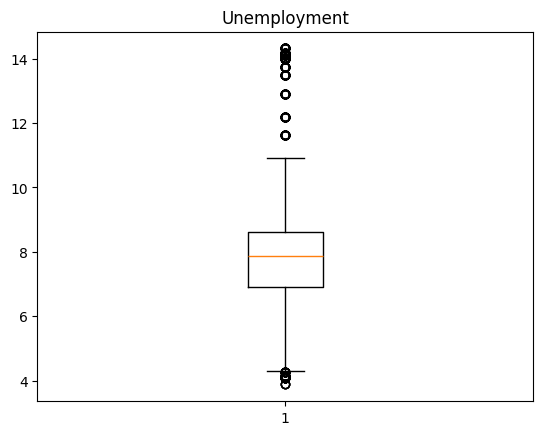

In [11]:
cols = ["Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment"]

for i in cols:
    plt.boxplot(df[i])
    plt.title(i)
    plt.show()

### Sales and unemployment differ by store, so the boxplots are drawn per store.

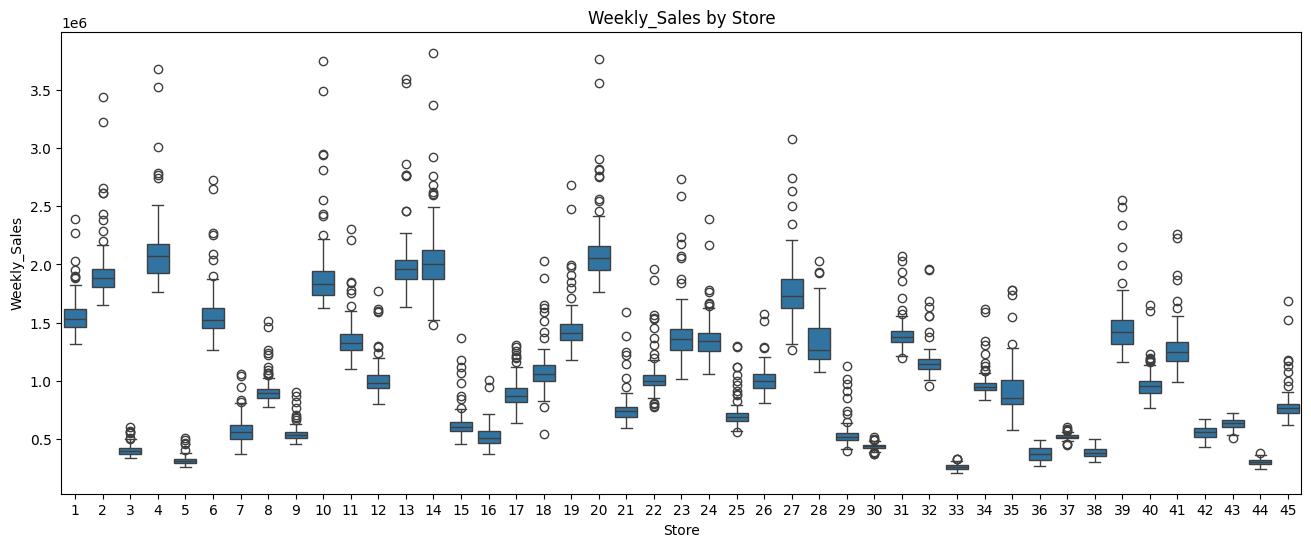

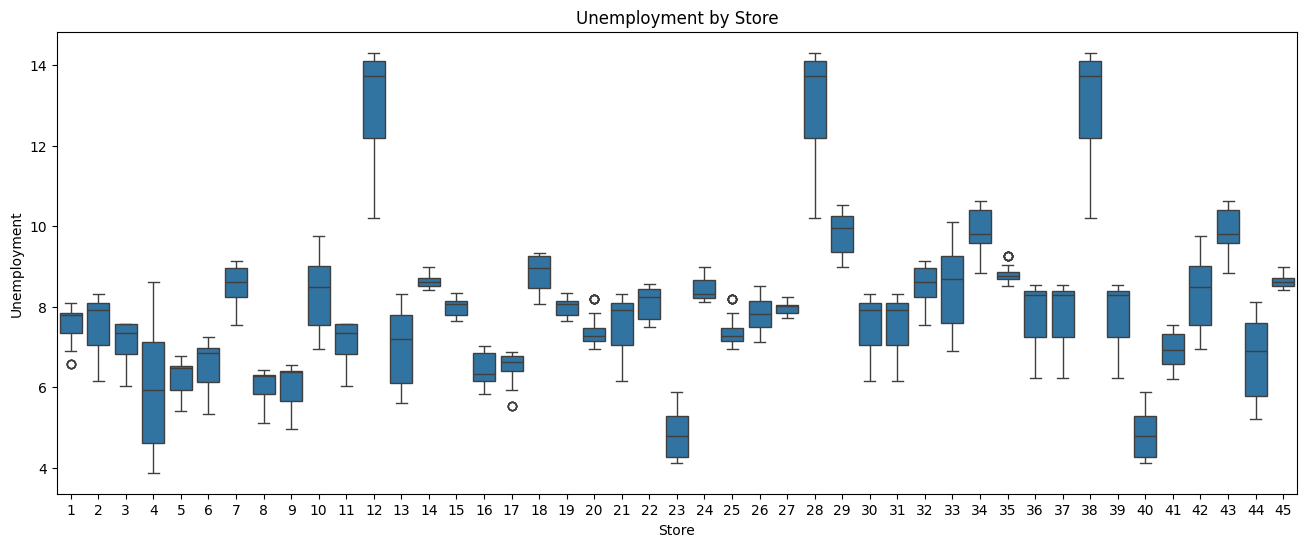

In [12]:
plt.figure(figsize=(16, 6))
sns.boxplot(x="Store", y="Weekly_Sales", data=df)
plt.title("Weekly_Sales by Store")
plt.show()

plt.figure(figsize=(16, 6))
sns.boxplot(x="Store", y="Unemployment", data=df)
plt.title("Unemployment by Store")
plt.show()

## Outlier Analysis

**Method:** Boxplots of the numeric columns, first for all rows together and then grouped by store (`Weekly_Sales` and `Unemployment`).

### Weekly_Sales
- Sales levels differ a lot between stores. Stores 4, 20, 14, 13, 2 and 10 are the highest, at about 1.8M to 2.1M a week. Stores 33, 44, 5, 3, 36 and 38 are the lowest, at about 0.25M to 0.4M.
- Almost every store has outliers on the **high** side and very few on the low side.
- The highest value, about 3.8M, belongs to Store 14.
- Some stores (33, 44, 30) have steady sales. Others (28, 35) vary a lot.
- The pooled boxplot hid these differences, so outliers should be judged **per store**.
- Interpretation: the high values look like genuine high-sales weeks (likely holiday weeks), not errors. This is checked against `Holiday_Flag` below.

### Unemployment
* The IQR method identifies unemployment values below approximately 4.29 and above 11.22 as statistical outliers. These observations mainly come from stores with relatively high or low unemployment values.

* These values are not necessarily data errors. They may represent genuine differences between stores or regions.

* therefore :  

 No outliers are removed at this stage. The sales spikes are likely real events, and the high unemployment reflects regional differences.


In [13]:
Q1 = df["Weekly_Sales"].quantile(0.25)
Q3 = df["Weekly_Sales"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower)
print("Upper limit:", upper)

Q1: 553350.105
Q3: 1420158.66
IQR: 866808.5549999999
Lower limit: -746862.7275
Upper limit: 2720371.4924999997


Upper limit is about 2.72M. Rows above it are checked against `Holiday_Flag`

In [14]:
outliers = df[df["Weekly_Sales"] > upper]

print(len(outliers))
print(outliers["Holiday_Flag"].value_counts())
outliers[["Store", "Date", "Weekly_Sales", "Holiday_Flag"]].sort_values("Weekly_Sales", ascending=False)

34
Holiday_Flag
0    25
1     9
Name: count, dtype: int64


,Store,Date,Weekly_Sales,Holiday_Flag
1905,14,2010-12-24,3818686.45,0
2763,20,2010-12-24,3766687.43,0
1333,10,2010-12-24,3749057.69,0
527,4,2011-12-23,3676388.98,0
1762,13,2010-12-24,3595903.20,0
1814,13,2011-12-23,3556766.03,0
2815,20,2011-12-23,3555371.03,0
475,4,2010-12-24,3526713.39,0
1385,10,2011-12-23,3487986.89,0
189,2,2010-12-24,3436007.68,0


**Result:** 34 weeks are above the upper limit (2.72M). 9 of them are holiday weeks and 25 are not.

In [15]:
Q1_u = df["Unemployment"].quantile(0.25)
Q3_u = df["Unemployment"].quantile(0.75)
IQR_u = Q3_u - Q1_u

lower_u = Q1_u - 1.5 * IQR_u
upper_u = Q3_u + 1.5 * IQR_u

print("Lower limit:", lower_u)
print("Upper limit:", upper_u)

outliers_u = df[(df["Unemployment"] > upper_u) | (df["Unemployment"] < lower_u)]

print(len(outliers_u))
print(outliers_u["Store"].value_counts())

Lower limit: 4.2945
Upper limit: 11.218499999999999
481
Store
12    126
28    126
38    126
23     43
40     43
4      17
Name: count, dtype: int64


Limits are about 4.29 and 11.22. Outliers come from stores 12, 28 and 38 (high) and stores 23, 40 and 4 (low). These reflect regional differences, not errors, so they are kept.

### 1.4 Feature extraction
Year, Month and Week were taken from `Date` for the seasonality analysis.

In [16]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week

df[["Date", "Year", "Month", "Week"]].head()

,Date,Year,Month,Week
0,2010-02-05,2010,2,5
1,2010-02-12,2010,2,6
2,2010-02-19,2010,2,7
3,2010-02-26,2010,2,8
4,2010-03-05,2010,3,9


#### Sales outliers: when and where
- All 34 outliers fall in November (9) and December (25).
- 28 of the 34 come from five large stores: 20 (7), 13 (6), 4 (6), 10 (5) and 14 (4).
- They are end-of-year spikes in big stores, so they are kept.

## 1.5 Insights

Month
1     9.238846e+05
2     1.053200e+06
3     1.013309e+06
4     1.026762e+06
5     1.031714e+06
6     1.064325e+06
7     1.031748e+06
8     1.048017e+06
9     9.893353e+05
10    9.996321e+05
11    1.147266e+06
12    1.281864e+06
Name: Weekly_Sales, dtype: float64


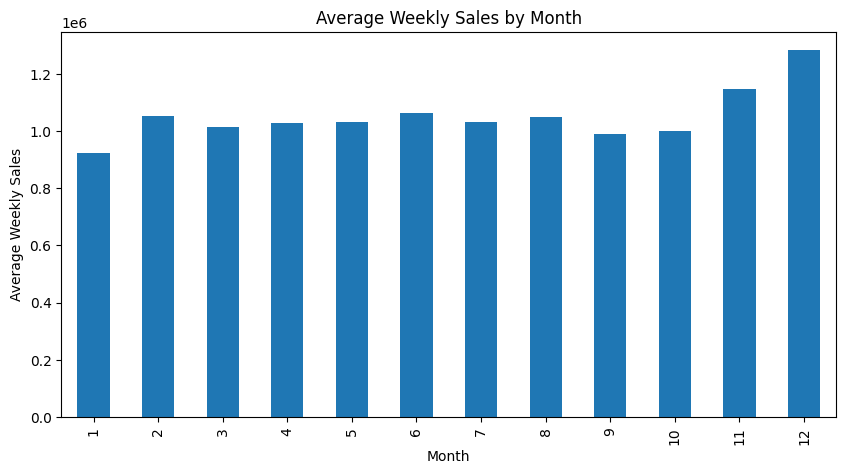

In [17]:
monthly = df.groupby("Month")["Weekly_Sales"].mean()
print(monthly)

plt.figure(figsize=(10, 5))
monthly.plot(kind="bar")
plt.title("Average Weekly Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Weekly Sales")
plt.show()

#### (b) Seasonality
- Average weekly sales are highest in December and November, and lowest in January.
- February to October stays fairly flat, with a small dip in September and October.
- Likely reason: holiday shopping at the end of the year, followed by a post-holiday drop in January.


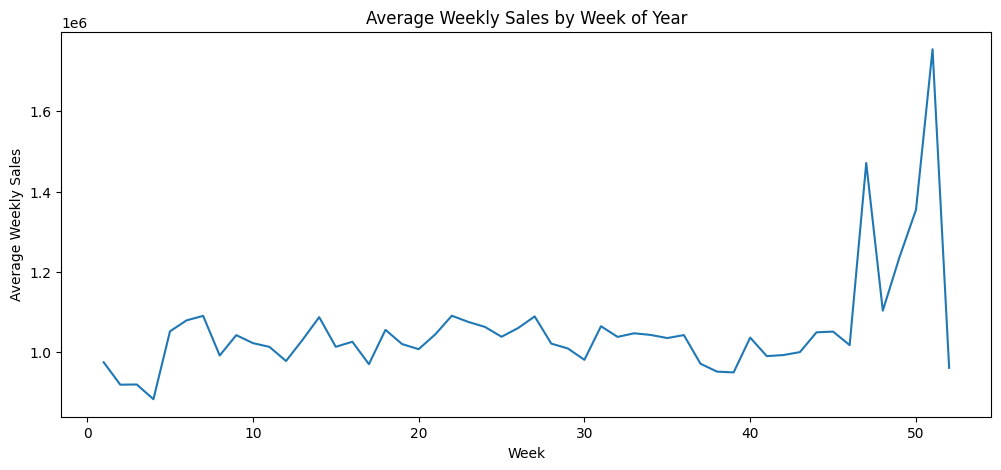

In [18]:
weekly = df.groupby("Week")["Weekly_Sales"].mean()

plt.figure(figsize=(12, 5))
weekly.plot()
plt.title("Average Weekly Sales by Week of Year")
plt.xlabel("Week")
plt.ylabel("Average Weekly Sales")
plt.show()

**Weekly view**
- Weeks 5 to 45 are steady, at about 1.0M to 1.1M.
- Sales spike at week 47 (late November, Thanksgiving and Black Friday).
- The highest point is week 51 (the week before Christmas), at about 1.75M.
- Sales drop sharply in week 52 (after Christmas).

In [19]:
print(df[df["Holiday_Flag"] == 1]["Week"].value_counts().sort_index())

Week
6     135
36    135
47     90
52     90
Name: count, dtype: Int64


**Holiday weeks in the dataset:** weeks 6, 36, 47 and 52 are flagged. Only week 47 shows a big spike. Week 52 is low, and the highest week (51) is not flagged.

## **Seasonality**

**Monthly view**
- Average weekly sales are highest in December (about 1.28M) and November (about 1.15M).
- January is the lowest (about 0.92M). December is about 39% higher than January.
- February to October stays fairly flat, at about 1.0M to 1.06M.

**Weekly view**
- Weeks 5 to 45 are steady, at about 1.0M to 1.1M.
- Sales spike at week 47 (late November, Thanksgiving and Black Friday).
- The highest point is week 51 (the week before Christmas), at about 1.75M.
- Sales drop sharply in week 52 (after Christmas).

**Outliers**
- All 34 high-sales outliers fall in November (9) and December (25).
- 28 of the 34 come from five large stores: 20, 13, 4, 10 and 14.
- Only 9 of the 34 are flagged as holiday weeks.

**Conclusion:** - sales are Seasonal and The dataset flags weeks 6, 36, 47 and 52 as holidays. Only week 47 shows a big spike. Week 52 is low, and the highest week (51, the week before Christmas) is not flagged.

In [20]:
print(df["Unemployment"].corr(df["Weekly_Sales"]))

store_corr = df.groupby("Store").apply(lambda x: x["Unemployment"].corr(x["Weekly_Sales"]))
print(store_corr.sort_values())

-0.10617608965795429
Store
38   -0.785290
44   -0.780076
39   -0.384681
42   -0.356355
41   -0.350630
4    -0.337015
17   -0.263600
3    -0.230413
37   -0.221287
5    -0.207043
43   -0.201954
9    -0.191534
13   -0.171633
7    -0.165382
40   -0.112528
32   -0.099455
1    -0.097955
20   -0.095341
23   -0.077169
16   -0.070864
26   -0.066899
31   -0.064738
8    -0.052580
11   -0.020339
27   -0.014275
24   -0.012261
12   -0.009286
25   -0.004958
45   -0.004041
34    0.017010
22    0.039043
6     0.044251
2     0.066325
15    0.078905
29    0.084682
33    0.101175
19    0.101464
10    0.131908
28    0.136671
18    0.139179
30    0.201862
14    0.210786
21    0.218367
35    0.483865
36    0.833734
dtype: float64


### 1.5 (a) Unemployment vs Weekly Sales


* The overall correlation is -0.11, indicating a very weak negative linear relationship between unemployment and weekly sales across all stores.

* The relationship varies by store. Store 38 (-0.79) and Store 44 (-0.78) show strong negative correlations.

* A total of 29 out of 45 stores show negative correlations, although this does not establish causation.

* Stores 36 (+0.83) and 35 (+0.48) show positive correlations.

* These relationships may be influenced by seasonal patterns, time trends, and differences between stores.

In [21]:
print(df["Temperature"].corr(df["Weekly_Sales"]))

store_corr_temp = df.groupby("Store").apply(lambda x: x["Temperature"].corr(x["Weekly_Sales"]))
print(store_corr_temp.sort_values())

-0.06381001317946955
Store
10   -0.432569
12   -0.379416
3    -0.377524
28   -0.376506
30   -0.330816
8    -0.312324
37   -0.300493
2    -0.297673
34   -0.278523
11   -0.278503
20   -0.264983
31   -0.262192
4    -0.225583
1    -0.222701
9    -0.208343
45   -0.201945
14   -0.199851
21   -0.177084
5    -0.175517
42   -0.151639
18   -0.144278
13   -0.137746
29   -0.129144
32   -0.111681
36   -0.094454
6    -0.084863
22   -0.082892
19   -0.080805
15   -0.050541
25   -0.031311
7     0.015077
33    0.019244
38    0.032993
35    0.043392
23    0.056257
39    0.064738
17    0.081012
40    0.090598
43    0.095272
41    0.106761
24    0.111833
27    0.121809
16    0.182948
26    0.211722
44    0.267822
dtype: float64


### 1.5 (c) Temperature vs Weekly Sales
* The overall correlation is -0.06, indicating a negligible linear relationship between temperature and weekly sales.

* By store, 30 out of 45 stores show negative correlations. Store 10 has the strongest negative correlation (-0.43).

* Some stores show positive correlations, such as Store 44 (+0.27).

* The observed relationships may be influenced by seasonality because temperature and shopping patterns both vary throughout the year.

In [22]:
print(df["CPI"].corr(df["Weekly_Sales"]))

store_corr_cpi = df.groupby("Store").apply(lambda x: x["CPI"].corr(x["Weekly_Sales"]))
print(store_corr_cpi.sort_values())

-0.07263416204017632
Store
36   -0.915095
35   -0.424107
14   -0.419755
30   -0.298188
43   -0.285686
27   -0.213082
18   -0.193541
15   -0.174467
21   -0.163649
19   -0.155341
10   -0.115374
28   -0.095908
29   -0.072530
2    -0.062431
33   -0.052271
22   -0.038602
45   -0.023548
24   -0.013684
6    -0.011357
25   -0.010914
20    0.058706
11    0.069781
12    0.084087
23    0.084248
40    0.113318
34    0.115437
8     0.120255
16    0.124285
26    0.131980
31    0.132887
13    0.163976
32    0.196782
1     0.225408
37    0.244507
7     0.289044
9     0.294805
5     0.308261
3     0.317250
17    0.348571
4     0.351157
42    0.360859
41    0.392293
39    0.428043
44    0.740150
38    0.812837
dtype: float64


### 1.5 (d) CPI vs Weekly Sales
* The overall correlation is -0.07, indicating a negligible linear relationship between CPI and weekly sales.

* The relationship varies across stores: 20 stores show negative correlations and 25 show positive correlations.

* Store 36 has a strong negative correlation (-0.92), while Stores 38 and 44 have strong positive correlations.

* These store-level relationships may reflect time trends, regional differences, or other variables. Correlation alone cannot identify the underlying cause.

In [23]:
store_sales = df.groupby("Store")["Weekly_Sales"].mean().sort_values(ascending=False)

# (e) Top performing stores
print(store_sales.head(5))

# (f) Worst performing store and the gap
print(store_sales.tail(1))

highest = store_sales.iloc[0]
lowest = store_sales.iloc[-1]

print("Difference:", highest - lowest)
print("Highest is", highest / lowest, "times the lowest")

Store
20    2.107677e+06
4     2.094713e+06
14    2.020978e+06
13    2.003620e+06
2     1.925751e+06
Name: Weekly_Sales, dtype: float64
Store
33    259861.692028
Name: Weekly_Sales, dtype: float64
Difference: 1847815.1783216782
Highest is 8.110764052605244 times the lowest


### 1.5 (e) Top performing stores
Average weekly sales, highest first:
1. Store 20: about 2.11M
2. Store 4: about 2.09M
3. Store 14: about 2.02M
4. Store 13: about 2.00M
5. Store 2: about 1.93M

### 1.5 (f) Worst performing store and the gap
- Worst: Store 33, about 0.26M per week.
- The best store (20) sells about 1.85M more per week than the worst, about 8.1 times as much.
- Demand differs hugely across stores, so inventory should be planned store by store.

### Task 1: Summary of Insights

- **(a) Unemployment:** Very weak negative overall correlation with weekly sales (-0.11). Store-level relationships vary considerably.
- **(b) Seasonality:** Sales peak in November and December and are lowest in January.
- **(c) Temperature:** Negligible overall correlation with weekly sales (-0.06).
- **(d) CPI:** Negligible overall correlation with weekly sales (-0.07). Some stores show strong correlations that may reflect time trends or regional differences.
- **(e) Top-performing stores:** Stores 20, 4, 14, 13 and 2.
- **(f) Lowest-performing store:** Store 33. The highest-selling store has approximately 8.1 times the weekly sales of the lowest-selling store.
- **Outliers:** Observations were retained because they may represent genuine seasonal sales peaks or differences between stores and regions.

**Note:** Correlation indicates association, not causation. These results do not establish that unemployment, temperature or CPI directly causes changes in sales.

## Task 2: Forecasting the next 12 weeks for each store
The method is built on one store (Store 1) first and then repeated for all 45 stores.

### 2.1 Weekly series for Store 1
Sales are steady at about 1.4M to 1.65M with no clear trend, and two big spikes in December 2010 and December 2011.

(143, 1)


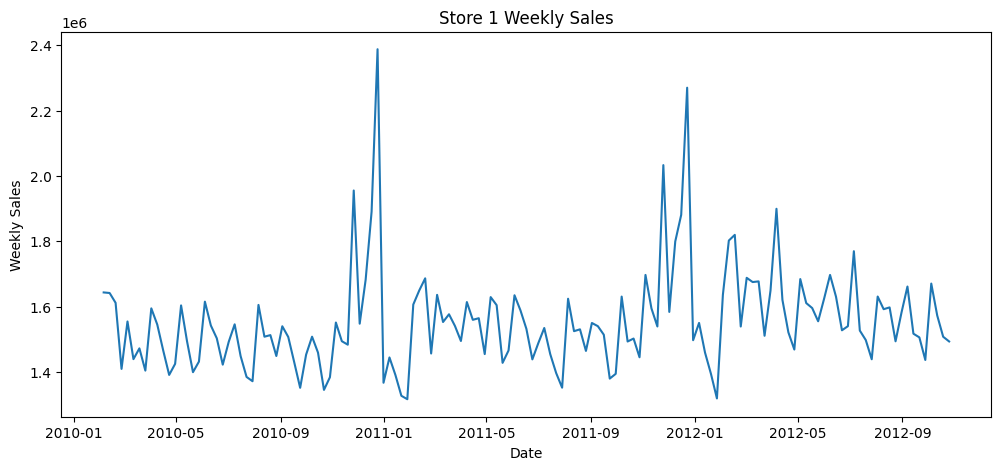

In [24]:
store1 = df[df["Store"] == 1][["Date", "Weekly_Sales"]]
store1 = store1.set_index("Date").sort_index()

print(store1.shape)

plt.figure(figsize=(12, 5))
plt.plot(store1["Weekly_Sales"])
plt.title("Store 1 Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

### 2.2 Stationarity check
ADF statistic about -5.10 and p-value about 0.00001 (below 0.05), so Store 1 is stationary and no differencing is needed (d = 0). The rolling mean is flat, and the rolling std rises around the December spikes.

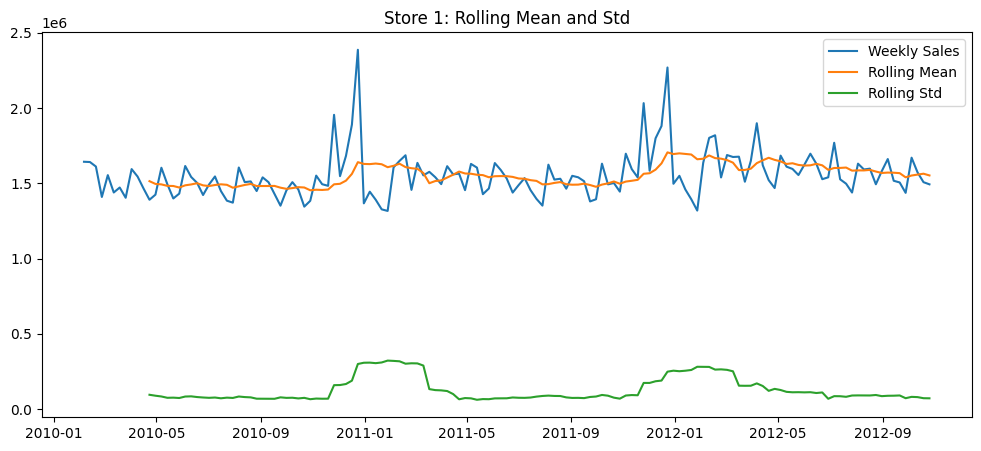

ADF statistic: -5.102186145192288
p-value: 1.3877788330759434e-05


In [25]:
from statsmodels.tsa.stattools import adfuller

rolling_mean = store1["Weekly_Sales"].rolling(window=12).mean()
rolling_std = store1["Weekly_Sales"].rolling(window=12).std()

plt.figure(figsize=(12, 5))
plt.plot(store1["Weekly_Sales"], label="Weekly Sales")
plt.plot(rolling_mean, label="Rolling Mean")
plt.plot(rolling_std, label="Rolling Std")
plt.legend()
plt.title("Store 1: Rolling Mean and Std")
plt.show()

result = adfuller(store1["Weekly_Sales"])
print("ADF statistic:", result[0])
print("p-value:", result[1])

### 2.3 Train and test split
The last 12 weeks are held out: 131 weeks for training and 12 for testing.

In [26]:
train = store1.iloc[:-12]
test = store1.iloc[-12:]

print(train.shape)
print(test.shape)

(131, 1)
(12, 1)


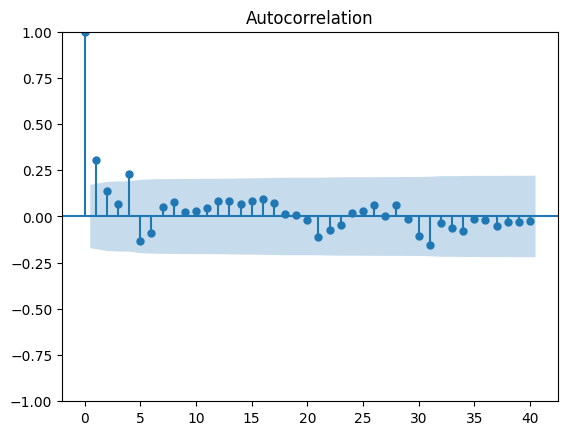

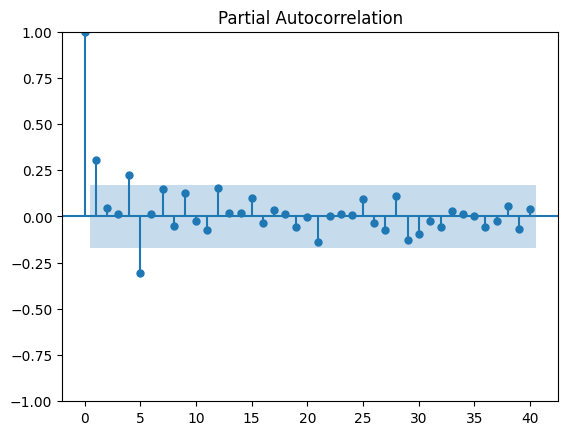

In [27]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(train["Weekly_Sales"], lags=40)
plt.show()

plot_pacf(train["Weekly_Sales"], lags=40)
plt.show()

### 2.4 ACF and PACF
Lags 1 and 4 stand out in the ACF, and lags 1, 4 and 5 in the PACF. The correlations are small (at most about 0.3), so ARIMA(1,0,1) is used as the starting model.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


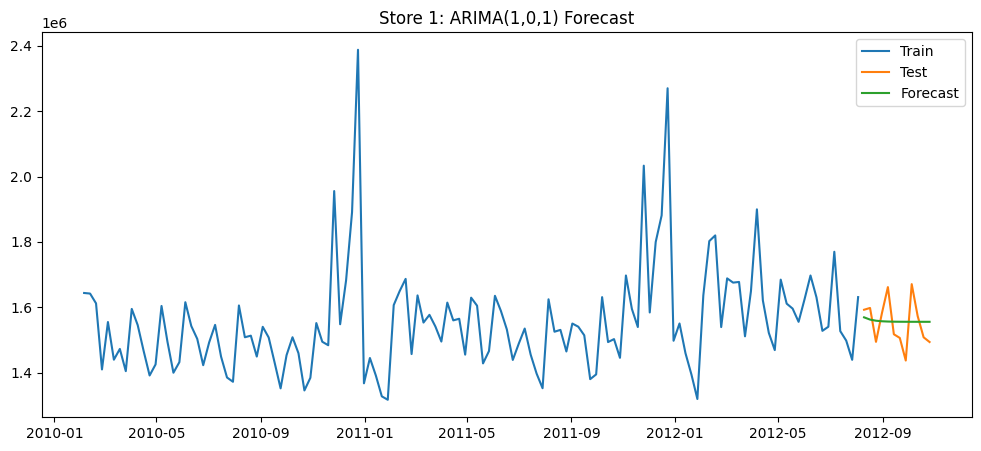

In [28]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

model = ARIMA(train["Weekly_Sales"], order=(1, 0, 1))
model_fit = model.fit()

forecast = model_fit.forecast(steps=12)

plt.figure(figsize=(12, 5))
plt.plot(train["Weekly_Sales"], label="Train")
plt.plot(test["Weekly_Sales"], label="Test")
plt.plot(test.index, forecast.values, label="Forecast")
plt.legend()
plt.title("Store 1: ARIMA(1,0,1) Forecast")
plt.show()

In [29]:
rmse = np.sqrt(mean_squared_error(test["Weekly_Sales"].values, forecast.values))
mape = np.mean(np.abs((test["Weekly_Sales"].values - forecast.values) / test["Weekly_Sales"].values)) * 100

print("RMSE:", rmse)
print("MAPE:", mape)

RMSE: 67937.90718166508
MAPE: 3.776053210638918


### 2.5 Baseline ARIMA(1,0,1)
RMSE about 68K and MAPE about 3.8%. This looks good only because the last 12 weeks are ordinary weeks: the forecast is nearly a flat line near the average.

(91, 1)
(12, 1)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


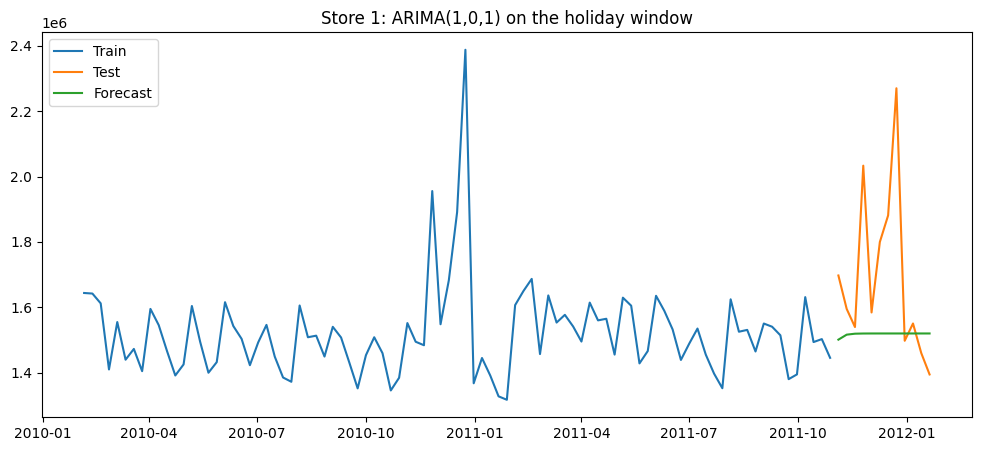

In [30]:
train2 = store1.loc[:"2011-10-28"]
test2 = store1.loc["2011-11-04":"2012-01-20"]

print(train2.shape)
print(test2.shape)

model2 = ARIMA(train2["Weekly_Sales"], order=(1, 0, 1)).fit()
forecast2 = model2.forecast(steps=12)

plt.figure(figsize=(12, 5))
plt.plot(train2["Weekly_Sales"], label="Train")
plt.plot(test2["Weekly_Sales"], label="Test")
plt.plot(test2.index, forecast2.values, label="Forecast")
plt.legend()
plt.title("Store 1: ARIMA(1,0,1) on the holiday window")
plt.show()

In [31]:
rmse2 = np.sqrt(mean_squared_error(test2["Weekly_Sales"].values, forecast2.values))
mape2 = np.mean(np.abs((test2["Weekly_Sales"].values - forecast2.values) / test2["Weekly_Sales"].values)) * 100

print("RMSE:", rmse2)
print("MAPE:", mape2)

RMSE: 303574.14011021337
MAPE: 10.962271734664384


### 2.6 Test on a holiday window
Train up to 28 Oct 2011 and test 4 Nov 2011 to 20 Jan 2012, the same time of year as the real forecast. ARIMA gives RMSE about 304K and MAPE about 11.0%. It is flat and misses both holiday peaks.

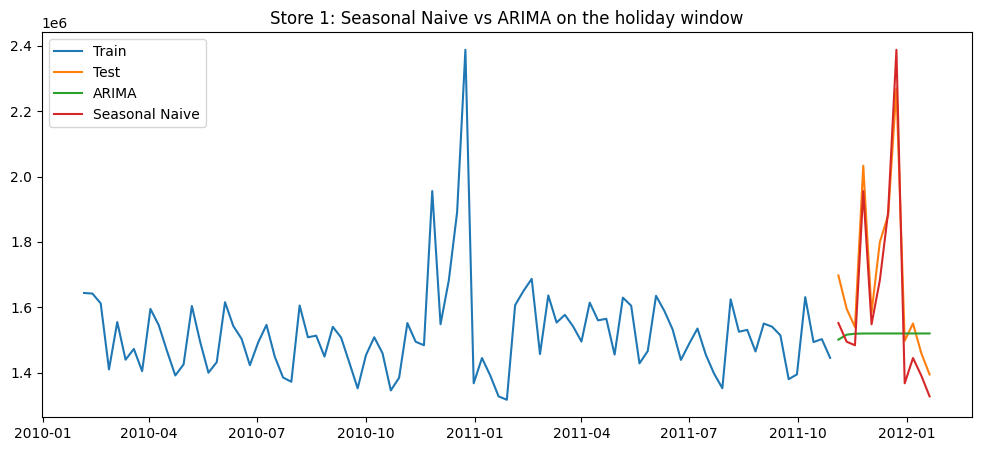

In [32]:
seasonal_naive = store1["Weekly_Sales"].shift(52).loc[test2.index]

plt.figure(figsize=(12, 5))
plt.plot(train2["Weekly_Sales"], label="Train")
plt.plot(test2["Weekly_Sales"], label="Test")
plt.plot(test2.index, forecast2.values, label="ARIMA")
plt.plot(test2.index, seasonal_naive.values, label="Seasonal Naive")
plt.legend()
plt.title("Store 1: Seasonal Naive vs ARIMA on the holiday window")
plt.show()

### 2.7 Seasonal naive baseline
Forecast = sales in the same week last year. RMSE about 94K and MAPE about 5.2%, much better than ARIMA. Capturing the yearly pattern matters more than the ARIMA order.

In [33]:
rmse3 = np.sqrt(mean_squared_error(test2["Weekly_Sales"].values, seasonal_naive.values))
mape3 = np.mean(np.abs((test2["Weekly_Sales"].values - seasonal_naive.values) / test2["Weekly_Sales"].values)) * 100

print("Seasonal Naive RMSE:", rmse3)
print("Seasonal Naive MAPE:", mape3)

Seasonal Naive RMSE: 94286.58917958234
Seasonal Naive MAPE: 5.1512160864377785


### 2.8 ARIMAX with holiday-week dummies
Dummy variables for weeks 47 to 52 (Thanksgiving to Christmas) are added to ARIMA. First attempt on the raw sales values: RMSE about 981K and MAPE about 42%. Every holiday-week forecast was far too high, even though the optimizer reported "converged".

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


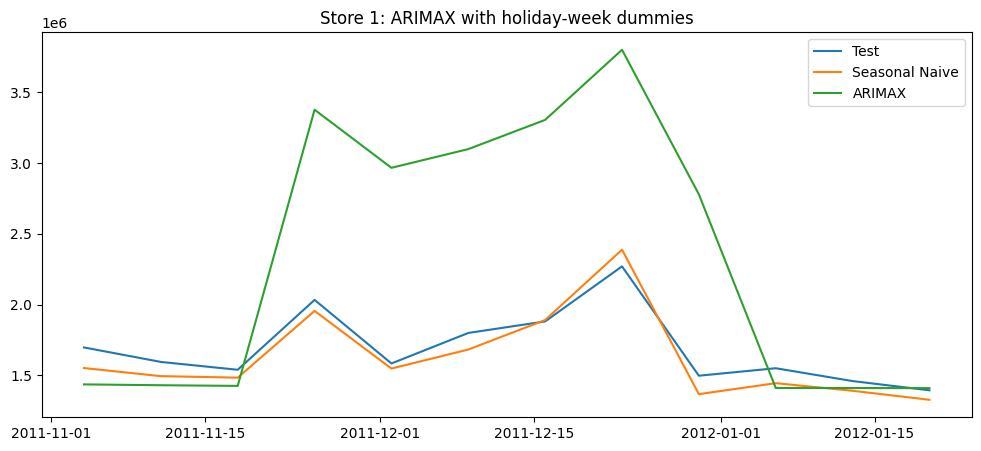

In [34]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

weeks = store1.index.isocalendar().week
exog = pd.DataFrame(
    {f"wk{w}": (weeks == w).astype(float) for w in range(47, 53)},
    index=store1.index
)

exog_train2 = exog.loc[train2.index]
exog_test2 = exog.loc[test2.index]

model4 = SARIMAX(train2["Weekly_Sales"], exog=exog_train2, order=(1, 0, 1), trend="c").fit(disp=False)
forecast4 = model4.forecast(steps=12, exog=exog_test2)

plt.figure(figsize=(12, 5))
plt.plot(test2["Weekly_Sales"], label="Test")
plt.plot(test2.index, seasonal_naive.values, label="Seasonal Naive")
plt.plot(test2.index, forecast4.values, label="ARIMAX")
plt.legend()
plt.title("Store 1: ARIMAX with holiday-week dummies")
plt.show()

In [35]:
rmse4 = np.sqrt(mean_squared_error(test2["Weekly_Sales"].values, forecast4.values))
mape4 = np.mean(np.abs((test2["Weekly_Sales"].values - forecast4.values) / test2["Weekly_Sales"].values)) * 100

print("ARIMAX RMSE:", rmse4)
print("ARIMAX MAPE:", mape4)

ARIMAX RMSE: 981223.5489490442
ARIMAX MAPE: 41.744339350507914


**Fix:** sales were divided by 1,000,000 before fitting, and the forecast was multiplied back. Result: RMSE about 100K and MAPE about 5.1%. The holiday effects are now sensible (about +0.46M for week 47, +0.89M for week 51 and -0.12M for week 52, on a base of about 1.40M).

In [36]:
print("Original converged:", model4.mle_retvals["converged"])

ys = train2["Weekly_Sales"] / 1e6
model5 = SARIMAX(ys, exog=exog_train2, order=(1, 0, 1), trend="c").fit(disp=False, maxiter=500)
print(model5.params)

forecast5 = model5.forecast(steps=12, exog=exog_test2) * 1e6

rmse5 = np.sqrt(mean_squared_error(test2["Weekly_Sales"].values, forecast5.values))
mape5 = np.mean(np.abs((test2["Weekly_Sales"].values - forecast5.values) / test2["Weekly_Sales"].values)) * 100

print("Scaled ARIMAX RMSE:", rmse5)
print("Scaled ARIMAX MAPE:", mape5)

Original converged: True


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


intercept    1.404168
wk47         0.459125
wk48         0.048435
wk49         0.182881
wk50         0.391325
wk51         0.888929
wk52        -0.121792
ar.L1        0.063700
ma.L1        0.224491
sigma2       0.006554
dtype: float64
Scaled ARIMAX RMSE: 100368.62558145485
Scaled ARIMAX MAPE: 5.080477721365086


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


intercept    0.204269
wk1         -0.082143
wk2         -0.139007
wk3         -0.208733
wk4         -0.226396
wk47         0.457819
wk48         0.046747
wk49         0.176231
wk50         0.379413
wk51         0.871694
wk52        -0.152691
ar.L1        0.864611
ma.L1       -0.756047
sigma2       0.005917
dtype: float64


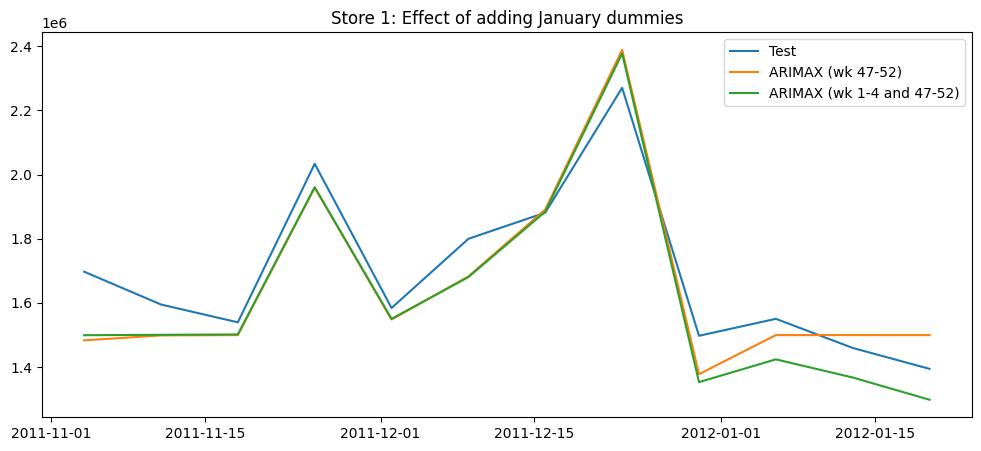

In [37]:
wk_list = [1, 2, 3, 4, 47, 48, 49, 50, 51, 52]
exog2 = pd.DataFrame(
    {f"wk{w}": (weeks == w).astype(float) for w in wk_list},
    index=store1.index
)

ys = train2["Weekly_Sales"] / 1e6
model6 = SARIMAX(ys, exog=exog2.loc[train2.index], order=(1, 0, 1), trend="c").fit(disp=False, maxiter=500)
print(model6.params)

forecast6 = model6.forecast(steps=12, exog=exog2.loc[test2.index]) * 1e6

plt.figure(figsize=(12, 5))
plt.plot(test2["Weekly_Sales"], label="Test")
plt.plot(test2.index, forecast5.values, label="ARIMAX (wk 47-52)")
plt.plot(test2.index, forecast6.values, label="ARIMAX (wk 1-4 and 47-52)")
plt.legend()
plt.title("Store 1: Effect of adding January dummies")
plt.show()

In [38]:
rmse6 = np.sqrt(mean_squared_error(test2["Weekly_Sales"].values, forecast6.values))
mape6 = np.mean(np.abs((test2["Weekly_Sales"].values - forecast6.values) / test2["Weekly_Sales"].values)) * 100

print("RMSE:", rmse6)
print("MAPE:", mape6)

RMSE: 106527.35035725037
MAPE: 5.68800852796926


Adding dummies for weeks 1 to 4 (January) gave RMSE about 106K and MAPE about 5.7%, which is slightly worse, so they were not used.

### 2.10 Final forecast for Store 1
The model is refitted on all 143 weeks and forecasts 2 Nov 2012 to 18 Jan 2013. Peaks are about 2.0M on 23 Nov and about 2.35M on 21 Dec, with a dip to about 1.46M on 28 Dec.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


2012-11-02    1.523800e+06
2012-11-09    1.525461e+06
2012-11-16    1.526671e+06
2012-11-23    1.999364e+06
2012-11-30    1.574397e+06
2012-12-07    1.752928e+06
2012-12-14    1.903289e+06
2012-12-21    2.352885e+06
2012-12-28    1.464381e+06
2013-01-04    1.529566e+06
2013-01-11    1.529662e+06
2013-01-18    1.529732e+06
Freq: W-FRI, Name: predicted_mean, dtype: float64


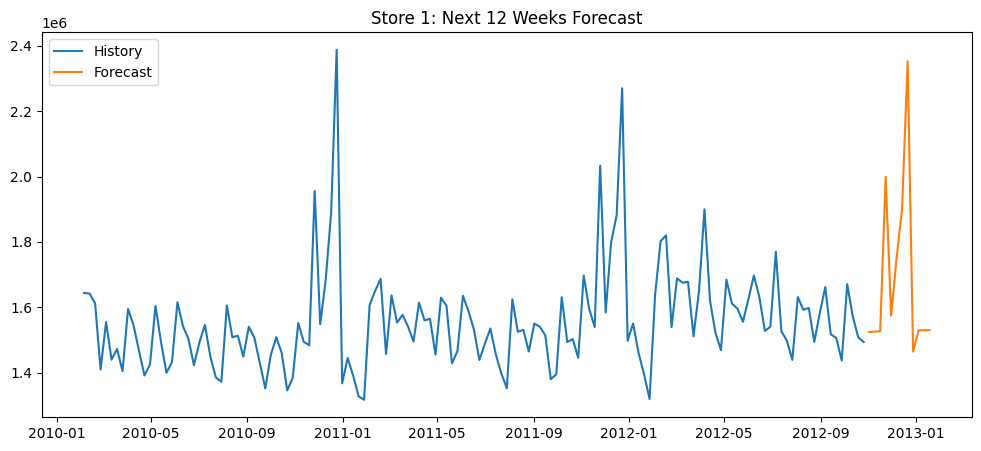

In [39]:
future_dates = pd.date_range(start="2012-11-02", periods=12, freq="W-FRI")
future_weeks = future_dates.isocalendar().week

exog_future = pd.DataFrame(
    {f"wk{w}": (future_weeks == w).astype(float) for w in range(47, 53)},
    index=future_dates
)

final_model = SARIMAX(store1["Weekly_Sales"] / 1e6, exog=exog, order=(1, 0, 1), trend="c").fit(disp=False, maxiter=500)
final_forecast = final_model.forecast(steps=12, exog=exog_future) * 1e6
final_forecast.index = future_dates

print(final_forecast)

plt.figure(figsize=(12, 5))
plt.plot(store1["Weekly_Sales"], label="History")
plt.plot(final_forecast, label="Forecast")
plt.legend()
plt.title("Store 1: Next 12 Weeks Forecast")
plt.show()

### 2.11 Forecast for all 45 stores
The same model is applied to every store. No forecast went above 1.5 times the store's historical maximum or below zero. Stores 42, 43 and 45 triggered a convergence warning.

In [40]:
forecasts = {}
flagged = []
not_converged = []

for s in sorted(df["Store"].unique()):
    y = df[df["Store"] == s].set_index("Date").sort_index()["Weekly_Sales"]

    model = SARIMAX(y / 1e6, exog=exog, order=(1, 0, 1), trend="c").fit(disp=False, maxiter=500)
    f = model.forecast(steps=12, exog=exog_future) * 1e6
    f.index = future_dates

    forecasts[s] = f

    if not model.mle_retvals["converged"]:
        not_converged.append(s)
    if f.max() > 1.5 * y.max() or f.min() < 0:
        flagged.append(s)

forecast_table = pd.DataFrame(forecasts)

print("Flagged stores:", flagged)
print("Not converged:", not_converged)

forecast_table.to_csv("walmart_12_week_forecast.csv")

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  

Flagged stores: []
Not converged: [np.int64(42), np.int64(43), np.int64(45)]


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


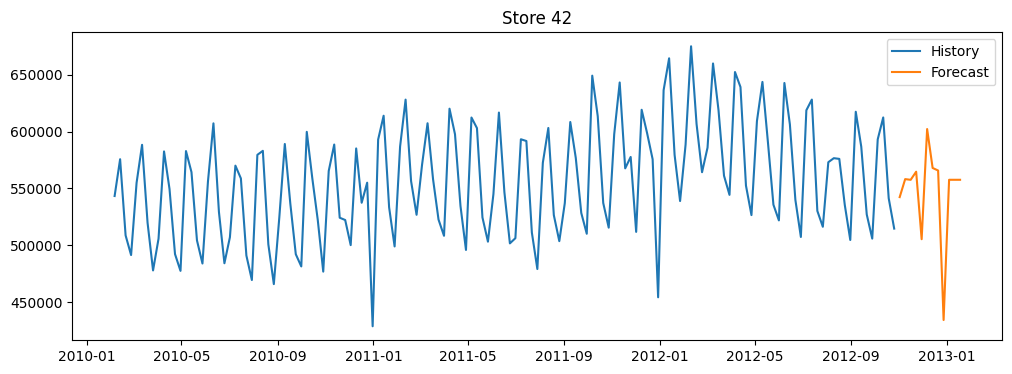

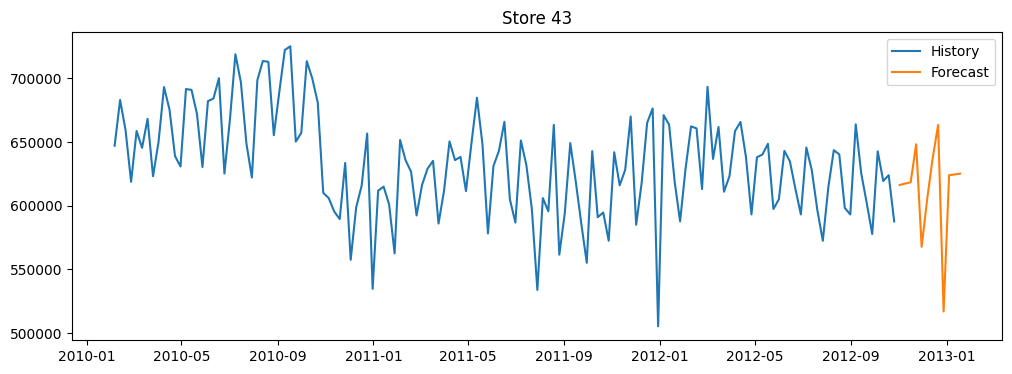

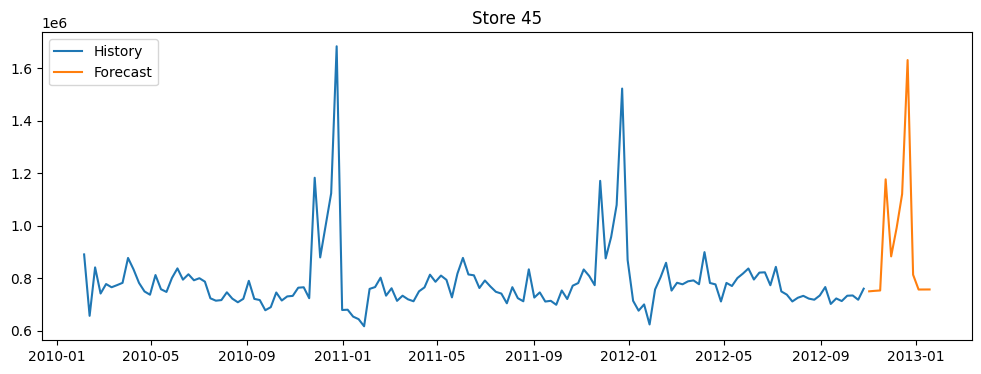

In [41]:
for s in [42, 43, 45]:
    y = df[df["Store"] == s].set_index("Date").sort_index()["Weekly_Sales"]
    plt.figure(figsize=(12, 4))
    plt.plot(y, label="History")
    plt.plot(forecast_table[s], label="Forecast")
    plt.title(f"Store {s}")
    plt.legend()
    plt.show()

The forecasts for stores 42, 43 and 45 follow each store's own history (its level, the dip at the end of December, and the big spikes for Store 45), so they were kept.

### 2.12 Business summary (all stores combined)

02 Nov 2012    45713136.0
09 Nov 2012    45803777.0
16 Nov 2012    45836071.0
23 Nov 2012    66424405.0
30 Nov 2012    50062237.0
07 Dec 2012    56247384.0
14 Dec 2012    61850885.0
21 Dec 2012    80185598.0
28 Dec 2012    44924534.0
04 Jan 2013    45845547.0
11 Jan 2013    45843344.0
18 Jan 2013    45841452.0
dtype: float64


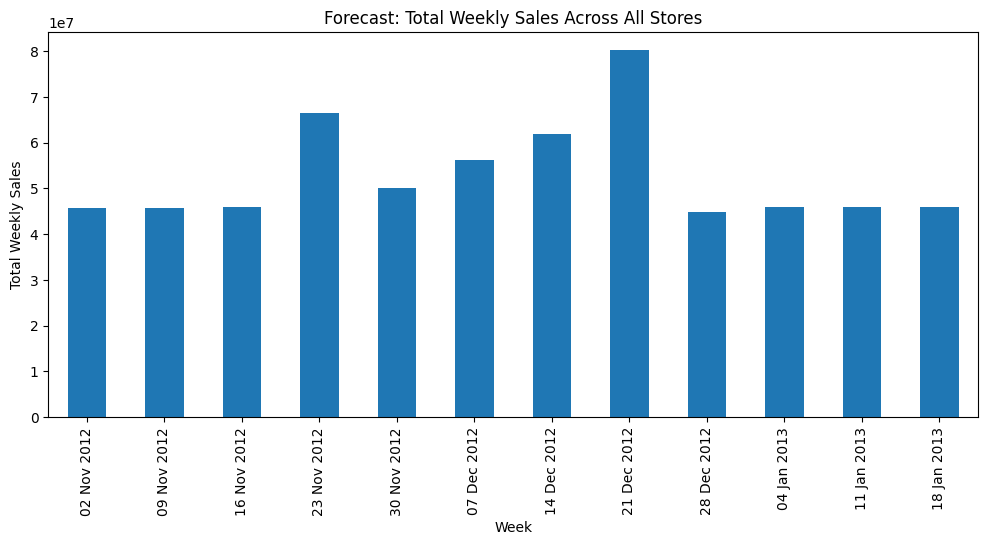

4     28594087.0
20    28578269.0
13    27727629.0
10    26591043.0
2     25904517.0
dtype: float64
Peak week: 21 Dec 2012
Peak vs normal week: 1.7513765347561157


In [42]:
weekly_total = forecast_table.sum(axis=1)
weekly_total.index = weekly_total.index.strftime("%d %b %Y")
print(weekly_total.round(0))

plt.figure(figsize=(12, 5))
weekly_total.plot(kind="bar")
plt.title("Forecast: Total Weekly Sales Across All Stores")
plt.xlabel("Week")
plt.ylabel("Total Weekly Sales")
plt.show()

top_stores = forecast_table.sum().sort_values(ascending=False).head(5)
print(top_stores.round(0))

normal_week = weekly_total.iloc[:3].mean()
print("Peak week:", weekly_total.idxmax())
print("Peak vs normal week:", weekly_total.max() / normal_week)

### Task 1: Summary of insights
- **(a) Unemployment:** weak overall effect (correlation -0.11). Most affected: Store 38 (-0.79) and Store 44 (-0.78).
- **(b) Seasonality:** sales peak in November and December (Thanksgiving and pre-Christmas shopping) and are lowest in January.
- **(c) Temperature:** almost no effect (-0.06). Negative values reflect the seasonal pattern, not temperature itself.
- **(d) CPI:** almost no overall effect (-0.07). Store 36 is strongly negative (-0.92) and stores 38 and 44 are strongly positive, probably a time-trend effect.
- **(e) Top stores:** 20, 4, 14, 13 and 2.
- **(f) Worst store:** Store 33. The best store sells about 8.1 times as much per week.
- Outliers were kept: they are genuine seasonal spikes and regional differences. No missing values or duplicates.

## Task 2: Summary

### Method
1. Prepared a weekly series for one store (Store 1) as a template.
2. Checked stationarity: rolling mean and std, and the ADF test (p-value about 0.00001, so stationary).
3. Used ACF and PACF to choose a starting order, ARIMA(1,0,1).
4. Tested models on a **holiday window**: trained on data up to 28 Oct 2011 and tested on the next 12 weeks (4 Nov 2011 to 20 Jan 2012), because the real forecast period (Nov 2012 to Jan 2013) includes Thanksgiving and Christmas.

### Model comparison (Store 1, holiday window)
| Model | RMSE | MAPE |
|---|---|---|
| ARIMA(1,0,1) | about 304K | about 11.0% |
| Seasonal Naive (same week last year) | about 94K | about 5.2% |
| ARIMAX with dummies for weeks 47-52 | about 100K | about 5.1% |
| ARIMAX with dummies for weeks 1-4 and 47-52 | about 106K | about 5.7% |

- Plain ARIMA predicts a flat line and misses the holiday peaks.
- The sales values are in the millions, so they were divided by 1,000,000 before fitting. Without this the optimizer produced wrong holiday effects.
- ARIMAX with weeks 47-52 was chosen: it matches the best score, and in the final forecast it averages the holiday effect over two past seasons (2010 and 2011). The January dummies did not improve the score, so they were dropped.

### Final model
ARIMAX(1,0,1) with a constant and dummy variables for weeks 47-52, fitted on all 143 weeks of each of the 45 stores. Forecast period: 2 Nov 2012 to 18 Jan 2013.

Stores 42, 43 and 45 showed convergence warnings. Their forecasts were checked visually and follow each store's history, so they were kept.

### Results (all 45 stores combined)
- Normal weeks: about 45.8M per week.
- Thanksgiving week (23 Nov): about 66.4M, about 45% above normal.
- Peak week (21 Dec, before Christmas): about 80.2M, about 1.75 times a normal week.
- After Christmas (28 Dec): about 44.9M, slightly below normal.
- Top stores by 12-week forecast: Store 4, Store 20, Store 13, Store 10, Store 2.

### Conclusion
- Demand is highly seasonal. Stock should be ready before Thanksgiving week and again before the week of 21 December, then cut back after Christmas.
- Stores differ by a factor of about 8 in size (best vs worst in Task 1), so inventory should be planned store by store.

### Limitations
- The model order and stationarity checks were done on Store 1 only, and the same settings were used for every store.
- There are only two past holiday seasons, so the holiday effects are based on very little data.
- The January weeks may be overestimated: January was the weakest month in the seasonality analysis, but the forecast treats it as a normal week.
- No prediction intervals were calculated.